# Bayesian comparison and coverage

Posterior estimates use uniform and Jeffreys Beta priors. Coverage is evaluated against the full public-sample rate difference under sampling without replacement.

Results are loaded from the saved analysis outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / 'results/full-run'
def table(name):
    frame = pd.read_csv(RESULTS / name)
    for column in frame.columns:
        if column == "two_sided_p_value":
            frame[column] = frame[column].map(lambda x: "< 1e-300" if x < 1e-300 else format(x, ".3g"))
        elif column.startswith("expected_loss_"):
            frame[column] = frame[column].map(lambda x: format(x, ".3e"))
    display(frame)
def figure(name):
    display(Image(filename=str(RESULTS / "figures" / name)))
def record(name):
    return json.loads((RESULTS / name).read_text())


,outcome,prior,prior_alpha,prior_beta,posterior_mean_difference,probability_positive,probability_positive_mc_standard_error,expected_loss_treatment,expected_loss_control,draws,ci_low,ci_high
0,visit,jeffreys,0.5,0.5,0.010342,1.0,0.0,0.000e+00,1.034e-02,100000,0.010053,0.010627
1,visit,uniform,1.0,1.0,0.010342,1.0,0.0,0.000e+00,1.034e-02,100000,0.010055,0.010628
2,conversion,jeffreys,0.5,0.5,0.001152,1.0,0.0,0.000e+00,1.152e-03,100000,0.001084,0.001219
3,conversion,uniform,1.0,1.0,0.001151,1.0,0.0,0.000e+00,1.152e-03,100000,0.001084,0.001219


,outcome,per_arm_n,reference_control_rate,reference_treatment_rate,reference_difference,wald_coverage,wald_coverage_mc_low,wald_coverage_mc_high,mean_wald_width,either_arm_zero_events,...,wald_interval_collapsed_mc_low,wald_interval_collapsed_mc_high,jeffreys_coverage,jeffreys_coverage_mc_low,jeffreys_coverage_mc_high,mean_jeffreys_width,uniform_coverage,uniform_coverage_mc_low,uniform_coverage_mc_high,mean_uniform_width
0,visit,500,0.038201,0.048543,0.010342,0.937,0.920205,0.950450,0.050360,0.000,...,2.168404e-19,0.003827,0.937,0.920205,0.950450,0.050929,0.939,0.922420,0.952220,0.051279
1,visit,2000,0.038201,0.048543,0.010342,0.960,0.945990,0.970489,0.025258,0.000,...,2.168404e-19,0.003827,0.958,0.943716,0.968779,0.025250,0.957,0.942581,0.967921,0.025387
2,visit,10000,0.038201,0.048543,0.010342,0.948,0.932444,0.960127,0.011279,0.000,...,2.168404e-19,0.003827,0.949,0.933565,0.960999,0.011267,0.945,0.929092,0.957503,0.011253
3,conversion,500,0.001938,0.003089,0.001152,0.885,0.863737,0.903317,0.011406,0.515,...,7.561390e-02,0.111509,0.976,0.964537,0.983820,0.014714,0.993,0.985622,0.996605,0.016850
4,conversion,2000,0.001938,0.003089,0.001152,0.944,0.927977,0.956625,0.006132,0.022,...,2.168404e-19,0.003827,0.946,0.930208,0.958379,0.006529,0.966,0.952865,0.975569,0.006814
5,conversion,10000,0.001938,0.003089,0.001152,0.953,0.938060,0.964473,0.002772,0.000,...,2.168404e-19,0.003827,0.949,0.933565,0.960999,0.002802,0.954,0.939188,0.965338,0.002832


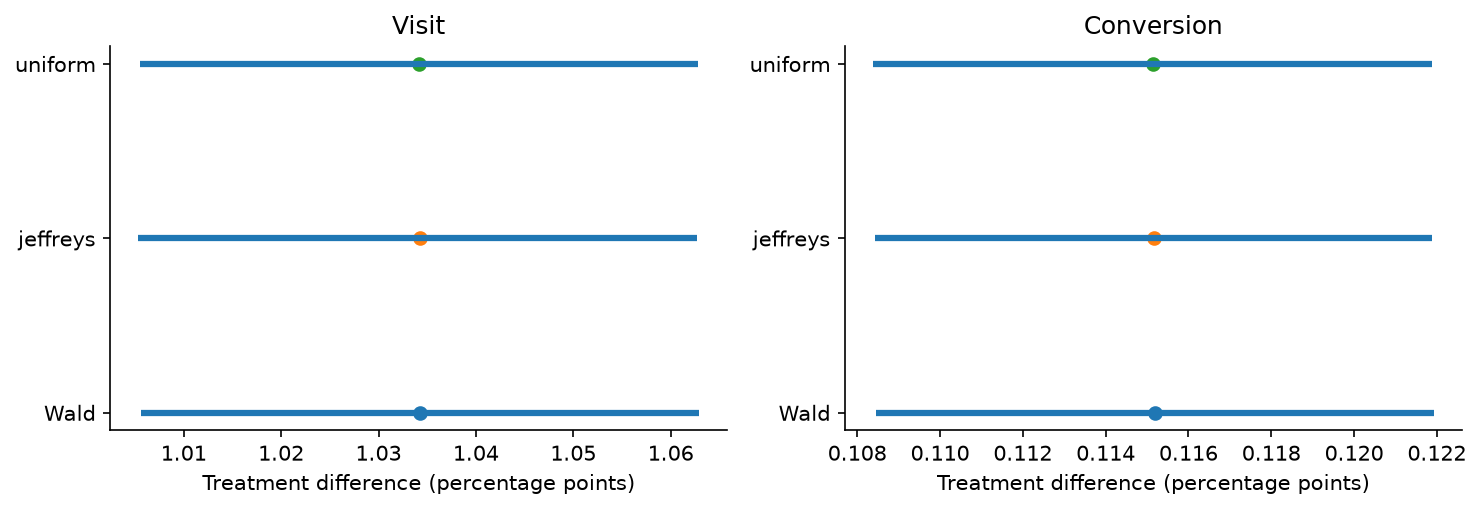

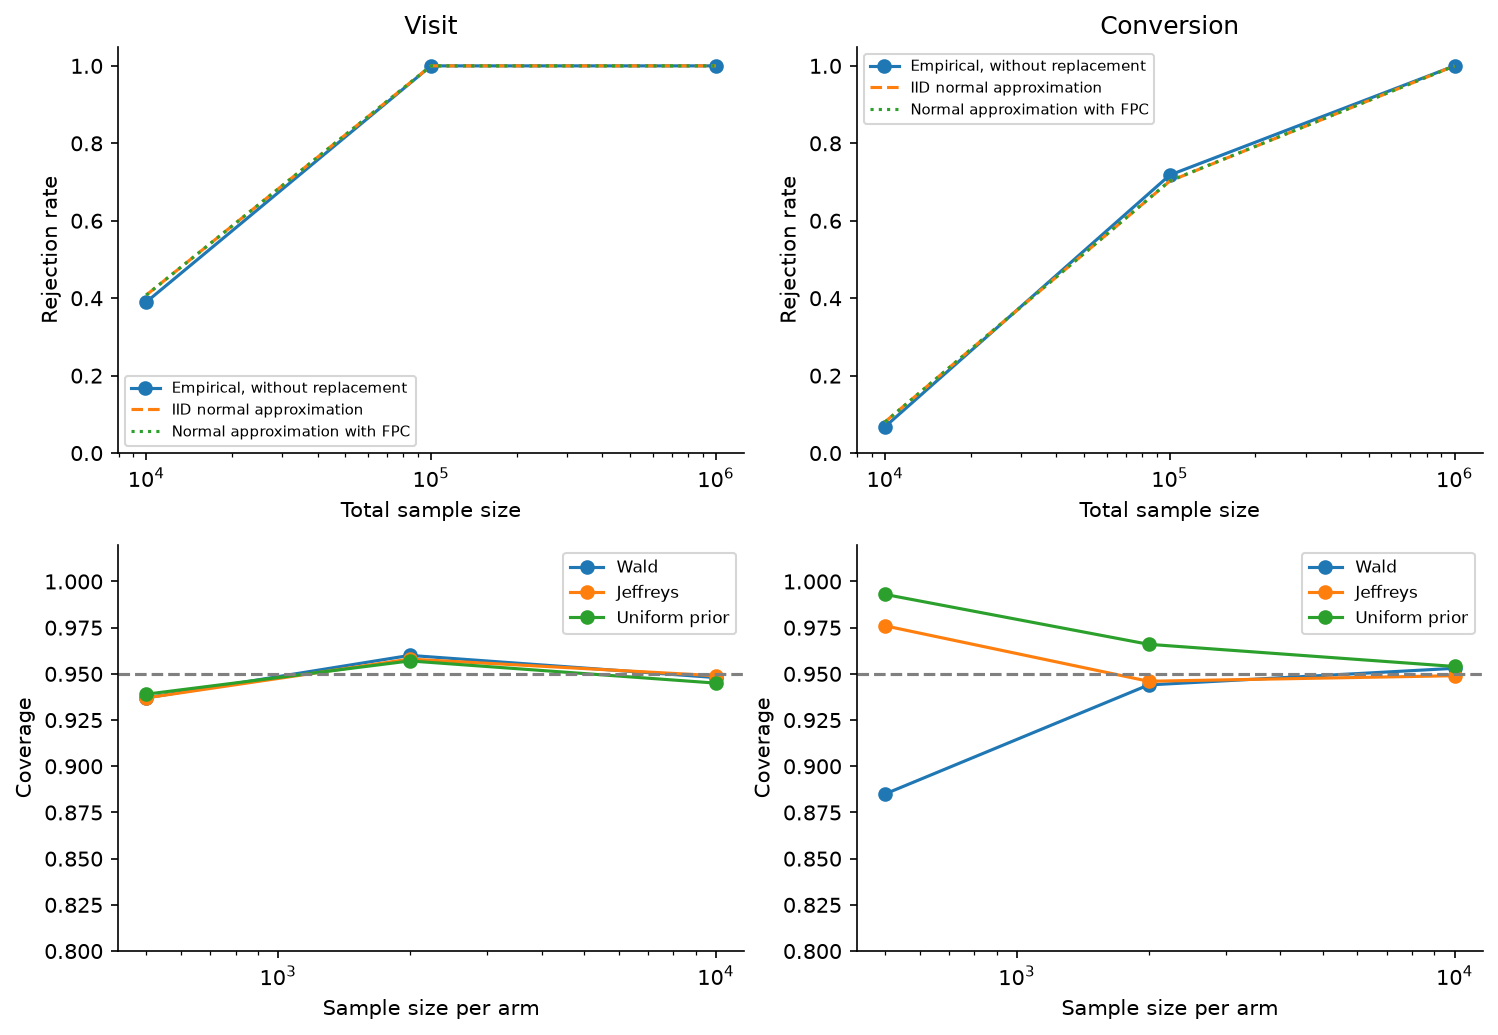

In [2]:
table("bayesian.csv")
table("coverage.csv")
figure("average_effects.png")
figure("power_coverage.png")

In [3]:
m = record("manifest.json")
display({k: m[k] for k in ["git", "data_sha256", "seeds", "hardware"]})

{'git': {'commit': '6928958aac539e9314c5d992203a826e9d1e5037',
  'source': 'local_repository',
  'working_tree_dirty': False,
  'release_source_matches': True},
 'data_sha256': '2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc',
 'seeds': {'analysis': 2026,
  'simulation_root': 2026,
  'split': 2026,
  'lightgbm': 2026,
  'targeting_tie_break': 2026,
  'uplift_row_bootstrap': 2027},
 'hardware': {'os': 'macOS-26.6.2-arm64-arm-64bit',
  'architecture': 'arm64',
  'cpu': 'Apple M4',
  'physical_cores': 10,
  'logical_cores': 10,
  'ram_bytes': 17179869184,
  'python': '3.12.14'}}